### Imports and Loading Model

In [1]:
# Import
from sentence_transformers import SentenceTransformer, util
import chromadb

In [2]:
# Load embedding model
model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")

### Indexing Data

In [3]:
documents = [
    "The Eiffel Tower is in Paris.",
    "The Colosseum is in Rome.",
    "The Statue of Liberty is in New York.",
    "The Burj Khalifa is in Dubai."
]

# Setup Chroma client and collection
chroma_client = chromadb.Client()
# Drop existing collection if it already exists
try:
    chroma_client.delete_collection("demo")
except:
    pass

# Now create fresh
collection = chroma_client.create_collection("demo")

# Add documents with embeddings
embeddings = model.encode(documents).tolist()
collection.add(documents=documents, embeddings=embeddings, ids=[str(i) for i in range(len(documents))])

print("Indexed documents:", documents)

Indexed documents: ['The Eiffel Tower is in Paris.', 'The Colosseum is in Rome.', 'The Statue of Liberty is in New York.', 'The Burj Khalifa is in Dubai.']


### Basic RAG Query

In [4]:
query = "Where is the Eiffel Tower located?"
query_emb = model.encode([query]).tolist()

results = collection.query(query_embeddings=query_emb, n_results=2)
print("\nBasic RAG Results:", results["documents"][0])


Basic RAG Results: ['The Eiffel Tower is in Paris.', 'The Burj Khalifa is in Dubai.']


### Hybrid Search + Reranking

In [5]:
# Hybrid = keyword match + semantic search (simple demo: filter + semantic rerank)
keyword_matches = [doc for doc in documents if "Eiffel" in doc or "Paris" in doc]

# Re-rank keyword matches by semantic similarity
scores = [(doc, util.cos_sim(model.encode(query), model.encode(doc)).item()) for doc in keyword_matches]
reranked = sorted(scores, key=lambda x: x[1], reverse=True)

print("\nHybrid Search + Reranking Results:")
for doc, score in reranked:
    print(f"{doc} (score={score:.4f})")


Hybrid Search + Reranking Results:
The Eiffel Tower is in Paris. (score=0.8500)


### Inside the Embeddings

In [6]:
import numpy as np

# The 4 vectors that cell 3 stored in Chroma, and the query's from cell 4: 384 numbers each
doc_vectors = np.array(embeddings)
query_vector = np.array(query_emb[0])

print("Embedding matrix shape:", doc_vectors.shape)
for i, vector in enumerate(doc_vectors):
    print(f"\nD{i+1}: {documents[i]}")
    print("Dimensions:", len(vector))
    print("First 10 values:", np.round(vector[:10], 4))

Embedding matrix shape: (4, 384)

D1: The Eiffel Tower is in Paris.
Dimensions: 384
First 10 values: [ 0.0711  0.0371  0.032  -0.011   0.0263 -0.0168 -0.0741  0.0014  0.0101
 -0.024 ]

D2: The Colosseum is in Rome.
Dimensions: 384
First 10 values: [ 0.0189  0.0055  0.031   0.0116 -0.0546 -0.0756 -0.097   0.0199 -0.0292
 -0.0227]

D3: The Statue of Liberty is in New York.
Dimensions: 384
First 10 values: [ 0.0873  0.0698  0.0379  0.0102  0.0369  0.0092 -0.0077 -0.0236  0.0042
 -0.0265]

D4: The Burj Khalifa is in Dubai.
Dimensions: 384
First 10 values: [ 0.0708  0.0313 -0.0076  0.0392  0.0041  0.0214 -0.0449 -0.0754  0.0199
 -0.0326]


### Cosine Similarity

In [7]:
from sklearn.metrics.pairwise import cosine_similarity

# Every document against every other: 1 on the diagonal, where each one meets itself
print("Documents vs documents:")
print(np.round(cosine_similarity(doc_vectors), 3))

# The query against each document
print("\nQuery vs documents:")
for i, score in enumerate(cosine_similarity([query_vector], doc_vectors)[0]):
    print(f"D{i+1}: {score:.3f}  {documents[i]}")

Documents vs documents:
[[1.    0.2   0.217 0.425]
 [0.2   1.    0.309 0.144]
 [0.217 0.309 1.    0.228]
 [0.425 0.144 0.228 1.   ]]

Query vs documents:
D1: 0.850  The Eiffel Tower is in Paris.
D2: 0.234  The Colosseum is in Rome.
D3: 0.264  The Statue of Liberty is in New York.
D4: 0.490  The Burj Khalifa is in Dubai.


### 2D Graph

2D coordinates:
D1: (-0.471, -0.216)  The Eiffel Tower is in Paris.
D2: (0.626, -0.506)  The Colosseum is in Rome.
D3: (0.535, 0.464)  The Statue of Liberty is in New York.
D4: (-0.249, 0.418)  The Burj Khalifa is in Dubai.
Q: (-0.441, -0.160)  Where is the Eiffel Tower located?


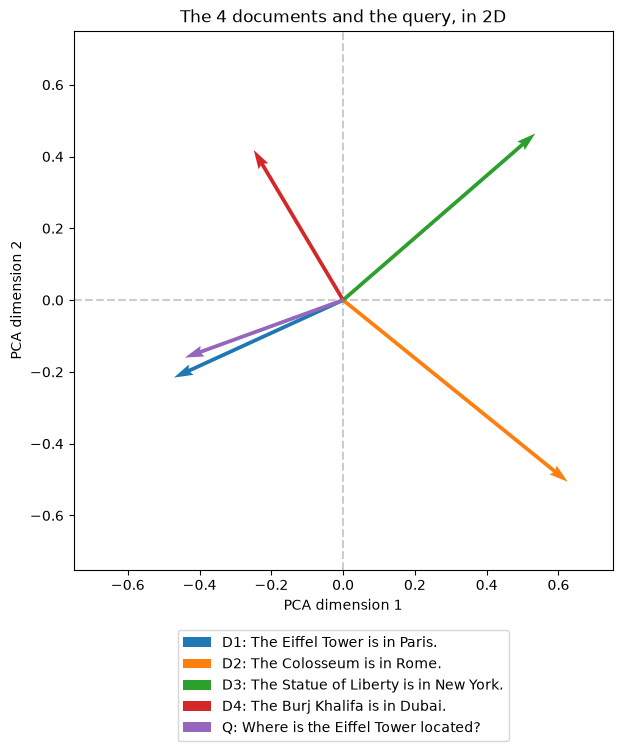

In [8]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 384 numbers can't be drawn: PCA keeps the 2 directions in which the 5 vectors differ most
vectors = np.vstack([doc_vectors, query_vector])
labels = [f"D{i+1}" for i in range(len(documents))] + ["Q"]
texts = documents + [query]
points_2d = PCA(n_components=2).fit_transform(vectors)

print("2D coordinates:")
for label, (x, y), text in zip(labels, points_2d, texts):
    print(f"{label}: ({x:.3f}, {y:.3f})  {text}")

# An arrow from the origin to each point, named in the legend below the graph
fig, ax = plt.subplots(figsize=(7, 7))
colors = plt.cm.tab10(range(len(labels)))
for label, (x, y), color, text in zip(labels, points_2d, colors, texts):
    ax.quiver(0, 0, x, y, angles="xy", scale_units="xy", scale=1, color=color, width=0.007, label=f"{label}: {text}")

limit = np.abs(points_2d).max() * 1.2
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)
ax.set_aspect("equal")
ax.set_title("The 4 documents and the query, in 2D")
ax.set_xlabel("PCA dimension 1")
ax.set_ylabel("PCA dimension 2")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

### Interactive 3D Graph

In [9]:
import plotly.express as px

# The same 5 vectors, down to 3 numbers each: drag the graph to turn it, hover over a point to read its text
points_3d = PCA(n_components=3).fit_transform(vectors)

print("3D coordinates:")
for label, (x, y, z) in zip(labels, points_3d):
    print(f"{label}: ({x:.3f}, {y:.3f}, {z:.3f})")

fig_3d = px.scatter_3d(
    x=points_3d[:, 0], y=points_3d[:, 1], z=points_3d[:, 2],
    text=labels, color=labels, hover_name=labels, hover_data={"Text": texts},
    title="The 4 documents and the query, in 3D",
    labels={"x": "PCA dimension 1", "y": "PCA dimension 2", "z": "PCA dimension 3"},
)
fig_3d.update_traces(marker=dict(size=7), textposition="top center")
fig_3d.update_layout(height=600, showlegend=False)
fig_3d.show()

3D coordinates:
D1: (-0.471, -0.216, 0.238)
D2: (0.626, -0.506, -0.258)
D3: (0.535, 0.464, 0.400)
D4: (-0.249, 0.418, -0.563)
Q: (-0.441, -0.160, 0.183)
